# 04 - Feature Engineering

**Objective:** improve the baseline by building features on customer behavior, time, amount, and email.

**Principles:**
- No feature uses the target.
- Per-customer features are **causal**: each transaction only uses *previous* transactions. This avoids leaking information from the future across train, validation, and test.
- For a fair comparison, the **same hyperparameters** as in the baseline are used.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.metrics import precision_recall_curve

from src.validation import add_day, temporal_split
from src.features import build_features, NEW_FEATURES, KEY_COLS
from src.evaluate import evaluate, evaluate_by_segment

sns.set_theme(style="whitegrid")

## 1. Feature construction

In [2]:
df = add_day(pd.read_parquet("../data/processed/train_merged.parquet"))
df = build_features(df)

# the remaining text columns must be 'category' for LightGBM
for c in df.columns:
    if not pd.api.types.is_numeric_dtype(df[c]):
        df[c] = df[c].astype("category")

print(df.shape)
df[NEW_FEATURES + KEY_COLS].describe(include="all").T.head(20)

(590540, 454)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hour,590540.0,NaN,NaN,NaN,13.861923,7.607152,0.0,6.0,16.0,20.0,23.0
dow,590540.0,NaN,NaN,NaN,2.95794,2.033973,0.0,1.0,3.0,5.0,6.0
amt_log,590540.0,NaN,NaN,NaN,4.38296,0.937183,0.223943,3.791459,4.24519,4.836282,10.371564
amt_frac,590540.0,NaN,NaN,NaN,0.379452,0.434118,0.0,0.0,0.0,0.949997,0.999001
n_missing,590540.0,NaN,NaN,NaN,195.622774,49.035963,24.0,208.0,211.0,229.0,340.0
P_email_provider,496084,44,gmail,228851,NaN,NaN,NaN,NaN,NaN,NaN,NaN
R_email_provider,137291,45,gmail,57242,NaN,NaN,NaN,NaN,NaN,NaN,NaN
email_match,126227.0,NaN,NaN,NaN,0.812061,0.390665,0.0,1.0,1.0,1.0,1.0
card_n_prev,590540.0,NaN,NaN,NaN,1136.236927,1978.491703,0.0,39.0,284.0,1282.0,14111.0
card_secs_since_prev,575695.0,NaN,NaN,NaN,172883.03125,715908.6875,0.0,990.0,6001.0,59059.5,15599674.0


## 2. Sanity checks
How many approximate customers were identified and how different the available history is in each segment.

In [3]:
print(f"unique card_key: {df['card_key'].nunique():,}")
print(f"unique uid :      {df['uid'].nunique():,}")
print(f"Transactions per uid (median): {df.groupby('uid').size().median():.0f}")

train, valid, test = temporal_split(df)
pd.DataFrame({
    name: part[["card_n_prev", "uid_n_prev"]].median()
    for name, part in {"train": train, "valid": valid, "test": test}.items()
}).rename_axis("median of previous transactions")

unique card_key: 14,845
unique uid :      222,452
Transactions per uid (median): 1


,train,valid,test
median of previous transactions,,,
card_n_prev,196.0,617.0,768.0
uid_n_prev,1.0,2.0,2.0


## 3. Relationship of the new features with fraud (train only)
Only train is examined so as not to use validation/test information.

In [4]:
tmp = train.copy()
tmp["card_n_prev_bin"] = pd.cut(tmp["card_n_prev"], [-1, 0, 1, 4, 19, 99, np.inf],
                                labels=["0", "1", "2-4", "5-19", "20-99", "100+"])
print(tmp.groupby("card_n_prev_bin", observed=True)["isFraud"].agg(["mean", "size"]).round(4))
print()
print(tmp.groupby("hour")["isFraud"].mean().round(4).to_string())

                   mean    size
card_n_prev_bin                
0                0.0227   13195
1                0.0248    9384
2-4              0.0248   19721
5-19             0.0275   47048
20-99            0.0345   75109
100+             0.0386  246144

hour
0     0.0321
1     0.0326
2     0.0357
3     0.0347
4     0.0499
5     0.0627
6     0.0747
7     0.0978
8     0.1008
9     0.0967
10    0.0755
11    0.0409
12    0.0300
13    0.0215
14    0.0243
15    0.0248
16    0.0297
17    0.0325
18    0.0344
19    0.0350
20    0.0338
21    0.0343
22    0.0326
23    0.0384


## 4. Training
Same hyperparameters as the baseline. The `card_key` and `uid` keys are not fed into the model (they are high-cardinality identifiers that do not generalize to new customers).

In [5]:
DROP = ["TransactionID", "TransactionDT", "day", "isFraud"] + KEY_COLS
features = [c for c in df.columns if c not in DROP]
print(len(features), "features")

X_train, y_train = train[features], train["isFraud"]
X_valid, y_valid = valid[features], valid["isFraud"]

params = dict(
    objective="binary", learning_rate=0.05, n_estimators=2000, num_leaves=64,
    colsample_bytree=0.5, subsample=0.8, subsample_freq=1,
    random_state=42, n_jobs=-1, verbose=-1,
)
model = lgb.LGBMClassifier(**params)
model.fit(
    X_train, y_train,
    eval_set=[(X_valid, y_valid)], eval_metric="auc",
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(100)],
)
print("Best iteration:", model.best_iteration_)

448 features


c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.908713	valid_0's binary_logloss: 0.0892883
[200]	valid_0's auc: 0.921195	valid_0's binary_logloss: 0.0847213
[300]	valid_0's auc: 0.9249	valid_0's binary_logloss: 0.0830812
[400]	valid_0's auc: 0.926187	valid_0's binary_logloss: 0.0824121
[500]	valid_0's auc: 0.926898	valid_0's binary_logloss: 0.0820182
[600]	valid_0's auc: 0.926793	valid_0's binary_logloss: 0.0820289
Early stopping, best iteration is:
[552]	valid_0's auc: 0.92706	valid_0's binary_logloss: 0.0818801
Best iteration: 552


## 5. Comparison against the baseline
The baseline values are those obtained in `03_baseline.ipynb`.

In [6]:
p_valid = model.predict_proba(X_valid)[:, 1]
res_fe = evaluate(y_valid, p_valid)

res_base = {"auc_pr": 0.6113, "auc_roc": 0.9251, "recall@prec50": 0.6026, "recall@prec80": 0.4450}
comp = pd.DataFrame({"baseline": res_base, "with features": {k: res_fe[k] for k in res_base}})
comp["improvement (abs.)"] = comp["with features"] - comp["baseline"]
comp.round(4)

,baseline,with features,improvement (abs.)
auc_pr,0.6113,0.6145,0.0032
auc_roc,0.9251,0.9271,0.0020
recall@prec50,0.6026,0.6188,0.0162
recall@prec80,0.4450,0.4274,-0.0176


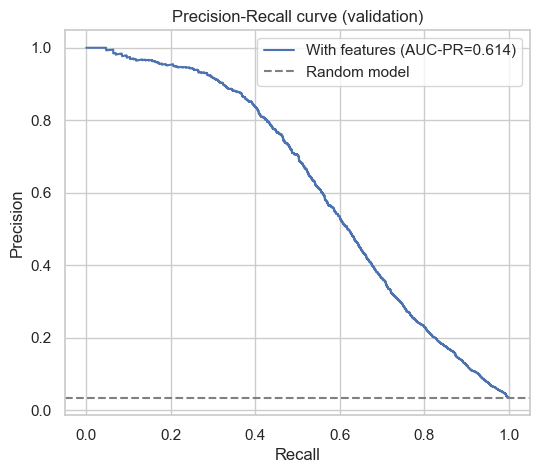

In [7]:
prec, rec, _ = precision_recall_curve(y_valid, p_valid)
plt.figure(figsize=(6, 5))
plt.plot(rec, prec, label=f"With features (AUC-PR={res_fe['auc_pr']:.3f})")
plt.axhline(y_valid.mean(), color="gray", linestyle="--", label="Random model")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-Recall curve (validation)")
plt.legend(); plt.show()

## 6. Performance by segment

In [8]:
evaluate_by_segment(valid, p_valid, "ProductCD")

,rows,frauds,rate_fraud_%,auc_pr,auc_roc
ProductCD,,,,,
C,8874,1123,12.6549,0.8102,0.9319
H,2270,135,5.9471,0.7352,0.9379
R,3245,161,4.9615,0.8629,0.9762
S,1347,86,6.3846,0.6353,0.9166
W,69567,1457,2.0944,0.3879,0.9044


In [9]:
evaluate_by_segment(valid, p_valid, "has_identity")

,rows,frauds,rate_fraud_%,auc_pr,auc_roc
has_identity,,,,,
0,70187,1496,2.1314,0.3924,0.9043
1,15116,1466,9.6983,0.8034,0.9428


## 7. Feature importance
In red, the features created in this notebook.

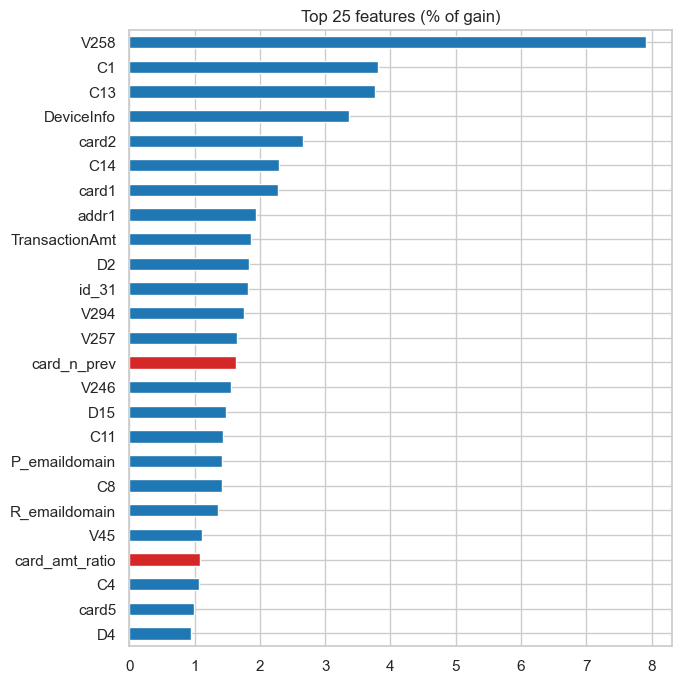

Total gain of the new features: 9.6%


In [10]:
imp = pd.Series(model.booster_.feature_importance(importance_type="gain"), index=features)
imp = (imp / imp.sum() * 100).sort_values(ascending=False)
top = imp.head(25).iloc[::-1]
colors = ["tab:red" if f in NEW_FEATURES else "tab:blue" for f in top.index]
top.plot(kind="barh", figsize=(7, 8), color=colors, title="Top 25 features (% of gain)")
plt.show()
print(f"Total gain of the new features: {imp[imp.index.isin(NEW_FEATURES)].sum():.1f}%")

## 8. Diagnosis of the `uid` identifier
The original `uid` (`card_key` + `addr1` + `day - D1`) ended up highly fragmented (median of 1 transaction per group). We compare variants to see which component causes the fragmentation: `addr1` (nulls and variants) or `day - D1`.

In [11]:
d1n = (df["day"].astype("float32") - df["D1"]).round()
tmp = df[["card_key", "addr1"]].assign(_d1n=d1n)

rows = []
for name, cols in {
    "card_key": ["card_key"],
    "card_key + addr1": ["card_key", "addr1"],
    "card_key + d1n": ["card_key", "_d1n"],
    "card_key + addr1 + d1n (actual)": ["card_key", "addr1", "_d1n"],
}.items():
    sizes = tmp.groupby(cols, dropna=False, observed=True).size()
    rows.append({
        "variant": name,
        "group": len(sizes),
        "median size": sizes.median(),
        "% groups with 1 transaction": 100 * (sizes == 1).mean(),
        "% of transactions in groups of 1": 100 * (sizes == 1).sum() / len(tmp),
    })
pd.DataFrame(rows).set_index("variant").round(2)

,group,median size,% groups with 1 transaction,% of transactions in groups of 1
variant,,,,
card_key,14845,4.0,27.48,0.69
card_key + addr1,42946,2.0,40.33,2.93
card_key + d1n,154181,2.0,47.97,12.52
card_key + addr1 + d1n (actual),222452,1.0,57.97,21.84


If one variant groups clearly better, it can be used with `build_features(df, uid_variant=...)` (options: `card_addr_d1n`, `card_d1n`, `card_addr`) and everything can be re-run from section 1.

## 9. Comparison with multiple seeds
A single run is not enough to claim that the features contribute: the difference may fall within the variation between seeds. Each configuration is trained with 3 seeds and the mean and standard deviation are compared. **This takes several minutes.**

In [12]:
base_features = [f for f in features if f not in NEW_FEATURES]
seeds = [1, 2, 3]

def fit_eval(feats, seed):
    m = lgb.LGBMClassifier(**{**params, "random_state": seed})
    m.fit(
        train[feats], y_train,
        eval_set=[(valid[feats], y_valid)], eval_metric="auc",
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    return evaluate(y_valid, m.predict_proba(valid[feats])[:, 1])

runs = {
    "baseline (no new features)": [fit_eval(base_features, s) for s in seeds],
    "with new features": [fit_eval(features, s) for s in seeds],
}

c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is dep

In [13]:
metrics = ["auc_pr", "auc_roc", "recall@prec50", "recall@prec80"]
summary = pd.DataFrame({
    name: {m: f"{np.mean([r[m] for r in res]):.4f} ± {np.std([r[m] for r in res]):.4f}" for m in metrics}
    for name, res in runs.items()
})
summary

,baseline (no new features),with new features
auc_pr,0.6172 ± 0.0040,0.6167 ± 0.0019
auc_roc,0.9276 ± 0.0004,0.9282 ± 0.0001
recall@prec50,0.6215 ± 0.0049,0.6133 ± 0.0066
recall@prec80,0.4326 ± 0.0068,0.4384 ± 0.0037


## 10. Conclusions

**Result:** the new features do not measurably improve the model.
With 3 seeds, PR-AUC 0.6172 ± 0.0040 (baseline) vs 0.6167 ± 0.0019 (with new features); ROC-AUC 0.9276 vs 0.9282. The differences are within the variation between seeds.

**Observations**
- A single run showed a +0.008 improvement in PR-AUC that disappeared when averaging across seeds: it was noise. The baseline's variation between seeds is ~0.004.
- The velocity features (`card_n_1h`, `card_n_24h`) are not among the most important.
- The approximate identifier `uid` (`card_key` + `addr1` + `day - D1`) generates 222,452 groups; 21.8% of transactions fall into single-transaction groups. `day - D1` is the main source of fragmentation.

**Hypothesis (not verified):** the dataset already includes behavioral features built by the company (`C` and `D` columns), so ours are redundant.

**Decision:** continue with the original features. The `features.py` code is kept as a documented experiment.

**Limitations:** causal features have a *cold start* at the beginning of the dataset; the `D1` heuristic is not officially documented; feature engineering on the `V` columns was not tested.